# Практична робота 17. Проста лінійна регресія

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr

# --- 1. Генерація набору даних (Варіант 1: Київ) ---
VARIANT = 1
np.random.seed(VARIANT)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", 
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
print("Перші 5 рядків згенерованого набору:")
print(climate.head())

Перші 5 рядків згенерованого набору:
  місто місяць  температура  опалювальні_дні  витрати_на_опалення
0  Київ    Січ           -4               24                  3.0
1  Київ    Лют           -3               20                  1.9
2  Київ    Бер            2               17                  0.2
3  Київ    Кві            9               12                  1.0
4  Київ    Тра           15                3                  0.2


## Завдання 1. Побудова регресійної моделі

In [2]:
X = climate["температура"]
Y = climate["витрати_на_опалення"]

reg_res = linregress(X, Y)
b0 = reg_res.intercept
b1 = reg_res.slope

print(f"Коефіцієнт зсуву (перетин, b0): {b0:.3f}")
print(f"Коефіцієнт нахилу (b1): {b1:.3f}")
print(f"Рівняння регресії: Витрати ≈ {b0:.3f} + ({b1:.3f}) × Температура")

Коефіцієнт зсуву (перетин, b0): 2.317
Коефіцієнт нахилу (b1): -0.124
Рівняння регресії: Витрати ≈ 2.317 + (-0.124) × Температура


## Завдання 2. Коефіцієнт детермінації

In [3]:
# 1. Через квадрат rvalue
r2_method1 = reg_res.rvalue ** 2

# 2. Через суми квадратів (SS_res / SS_tot)
Y_pred = b0 + b1 * X
ss_residual = np.sum((Y - Y_pred) ** 2)
ss_total = np.sum((Y - Y.mean()) ** 2)
r2_method2 = 1 - (ss_residual / ss_total)

print(f"R² через rvalue**2: {r2_method1:.4f}")
print(f"R² через формулу SS: {r2_method2:.4f}")

R² через rvalue**2: 0.6504
R² через формулу SS: 0.6504


## Завдання 3. Графік залишків і оцінка адекватності моделі

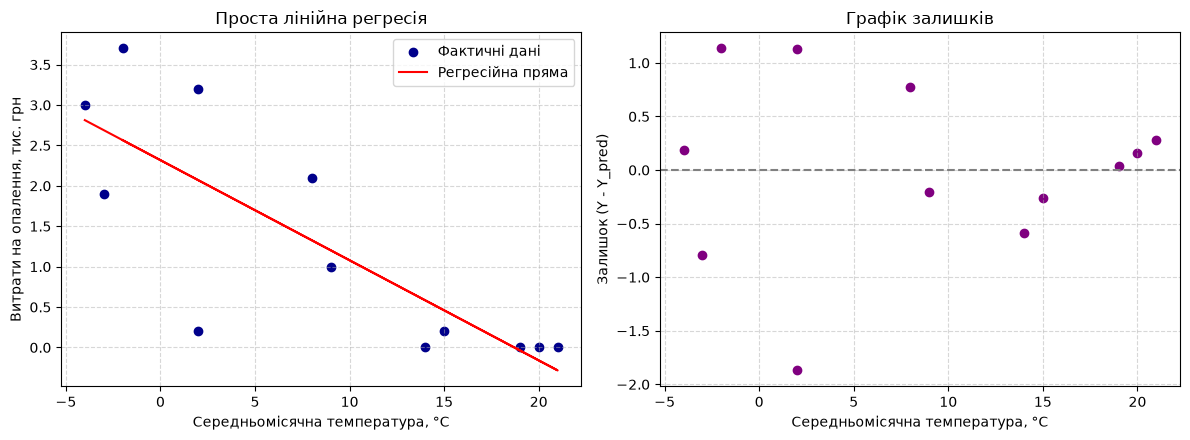

In [4]:
residuals = Y - Y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Регресійна пряма
ax1.scatter(X, Y, color="darkblue", label="Фактичні дані")
ax1.plot(X, Y_pred, color="red", label="Регресійна пряма")
ax1.set_xlabel("Середньомісячна температура, °C")
ax1.set_ylabel("Витрати на опалення, тис. грн")
ax1.set_title("Проста лінійна регресія")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Графік залишків
ax2.scatter(X, residuals, color="purple", label="Залишки")
ax2.axhline(0, color="gray", linestyle="--", linewidth=1.5)
ax2.set_xlabel("Середньомісячна температура, °C")
ax2.set_ylabel("Залишок (Y - Y_pred)")
ax2.set_title("Графік залишків")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Завдання 4. Прогноз і застереження щодо екстраполяції

In [5]:
temp_new = -10.0
cost_pred = b0 + b1 * temp_new

min_temp = X.min()
max_temp = X.max()

print(f"Прогнозовані витрати при температурі {temp_new} °C: {cost_pred:.3f} тис. грн")
print(f"Спостережений діапазон температур у вибірці: від {min_temp} °C до {max_temp} °C")

Прогнозовані витрати при температурі -10.0 °C: 3.556 тис. грн
Спостережений діапазон температур у вибірці: від -4 °C до 21 °C


## Завдання 5. Порівняння з коефіцієнтом кореляції

In [6]:
r_corr, p_corr = pearsonr(X, Y)
print(f"p-value з linregress: {reg_res.pvalue:.4e}")
print(f"p-value з pearsonr:   {p_corr:.4e}")

p-value з linregress: 1.5285e-03
p-value з pearsonr:   1.5285e-03
